### The largest eigen vector of covarinance matrix always points the direction of the largest variance of the data..

- steps
- 1. Mean centering
  2. finding covairiance matrix
  3. Finding the eigenvalues and vectors

   feature1  feature2  feature3  target
0 -1.576824 -0.869941 -1.085179       1
1 -0.200916 -0.675008 -0.241463       1
2  0.934870 -0.411107 -1.999559       1
3  1.657875  2.556987  0.450441       0
4  0.424759  0.170858  0.563752       1
(40, 4)


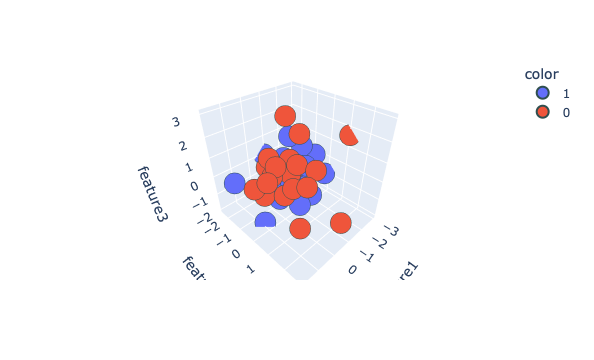

In [1]:

import numpy as np
import pandas as pd

mu_vec1 = np.array([0, 0, 0])
cov_mat1 = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
])

class1_sample = np.random.multivariate_normal(
    mu_vec1, cov_mat1, 20
)

df = pd.DataFrame(
    class1_sample,
    columns=['feature1', 'feature2', 'feature3']
)
df['target'] = 1

mu_vec2 = np.array([1, 1, 1])
cov_mat2 = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
])

class2_sample = np.random.multivariate_normal(
    mu_vec2, cov_mat2, 20
)

df1 = pd.DataFrame(
    class2_sample,
    columns=['feature1', 'feature2', 'feature3']
)
df1['target'] = 0

# Combine both classes
df = pd.concat([df, df1], ignore_index=True)

# Shuffle the rows
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(df.head())
print(df.shape)

     


import plotly.express as px
#y_train_trf = y_train.astype(str)
fig = px.scatter_3d(df, x=df['feature1'], y=df['feature2'], z=df['feature3'],
              color=df['target'].astype('str'))
fig.update_traces(marker=dict(size=12,
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))

fig.show()

In [2]:
# Step 1 - Apply standard scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

df.iloc[:,0:3] = scaler.fit_transform(df.iloc[:,0:3])


In [3]:
# Step 2 - Find Covariance Matrix
covariance_matrix = np.cov([df.iloc[:,0],df.iloc[:,1],df.iloc[:,2]])
print('Covariance Matrix:\n', covariance_matrix)

Covariance Matrix:
 [[1.02564103 0.32530536 0.21026176]
 [0.32530536 1.02564103 0.29185615]
 [0.21026176 0.29185615 1.02564103]]


In [4]:
# Step 3 - Finding EV and EVs
eigen_values, eigen_vectors = np.linalg.eig(covariance_matrix)

In [5]:
eigen_values

array([1.57993601, 0.81764118, 0.67934588])

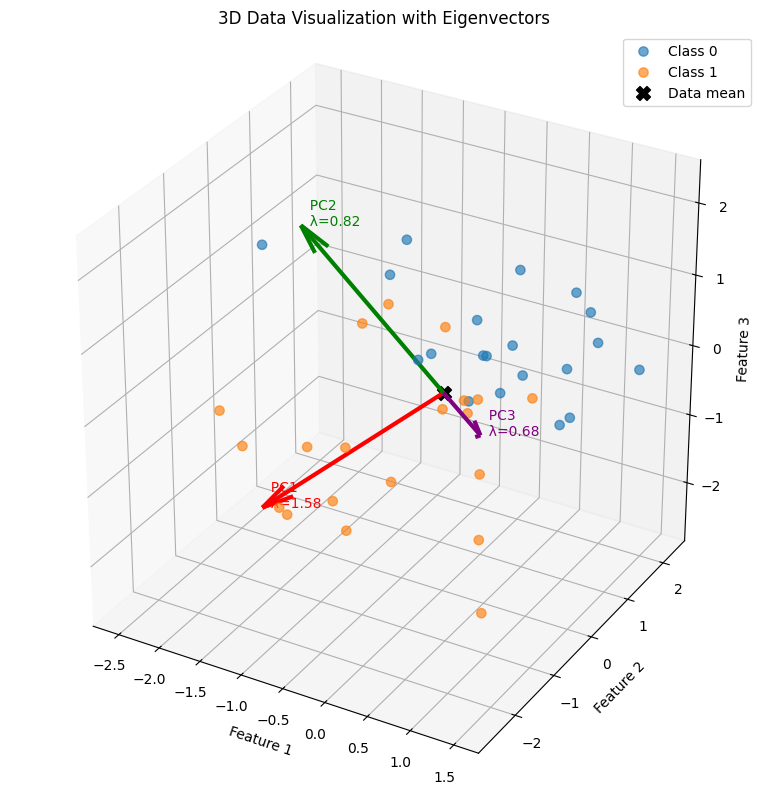

In [6]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Select the three features
features = ['feature1', 'feature2', 'feature3']
X = df[features].to_numpy()

# 2. Calculate the mean and covariance matrix
mean = X.mean(axis=0)
cov_mat = np.cov(X, rowvar=False)

# 3. Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_mat)

# Sort from largest eigenvalue to smallest
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# 4. Create the 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot both classes
for target in sorted(df['target'].unique()):
    mask = df['target'].to_numpy() == target
    ax.scatter(
        X[mask, 0], X[mask, 1], X[mask, 2],
        s=45, alpha=0.65,
        label=f'Class {target}'
    )

# 5. Plot the mean
ax.scatter(
    *mean, color='black', s=100,
    marker='X', label='Data mean'
)

# 6. Draw all three eigenvectors from the mean
colors = ['red', 'green', 'purple']
arrow_length = 2.5

for i in range(3):
    v = eigenvectors[:, i]

    ax.quiver(
        mean[0], mean[1], mean[2],
        v[0], v[1], v[2],
        length=arrow_length,
        normalize=True,
        color=colors[i],
        linewidth=3,
        arrow_length_ratio=0.15
    )

    # Label each eigenvector
    endpoint = mean + arrow_length * v
    ax.text(
        *endpoint,
        f'  PC{i+1}\n  λ={eigenvalues[i]:.2f}',
        color=colors[i],
        fontsize=10
    )

ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_zlabel('Feature 3')
ax.set_title('3D Data Visualization with Eigenvectors')
ax.legend()
ax.set_box_aspect((1, 1, 1))
plt.tight_layout()

plt.show()


In [7]:
pc = eigen_vectors[0:2]
pc

array([[-0.56873891, -0.63055812,  0.52814061],
       [-0.61898479, -0.0947321 , -0.77966894]])

In [8]:
transformed_df = np.dot(df.iloc[:,0:3],pc.T)
# 40,3 - 3,2 because of pc.T
new_df = pd.DataFrame(transformed_df,columns=['PC1','PC2'])
new_df['target'] = df['target'].values
new_df.head()

,PC1,PC2,target
0,0.593132,2.227081,1
1,0.238064,0.863112,1
2,-1.344620,1.543432,1
3,-2.193924,-0.907890,0
4,-0.152965,-0.135101,1


In [9]:
new_df.shape

(40, 3)

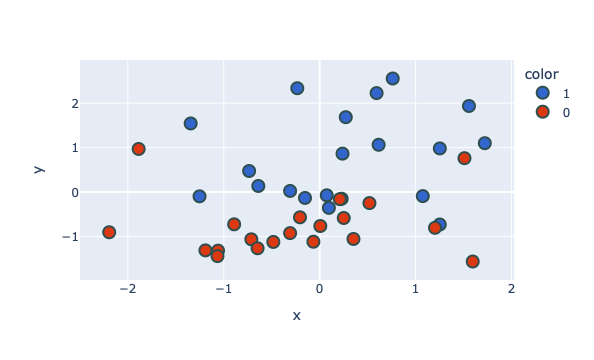

In [10]:
new_df['target'] = new_df['target'].astype('str')
fig = px.scatter(x=new_df['PC1'],
                 y=new_df['PC2'],
                 color=new_df['target'],
                 color_discrete_sequence=px.colors.qualitative.G10
                )

fig.update_traces(marker=dict(size=12,
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))
fig.show()
     
